# Name: Aman Mujahid
# Github Username: amanmujahid
# USC ID: 7092517106

## Question 1

### Time Series Classification Part 1: Feature Creation/Extraction

### (a)

In [1]:
import os
import numpy as np
import pandas as pd
import re

In [2]:
root = "../data/AReM"

activities = ["bending1", "bending2", "cycling", "lying", "sitting", "standing", "walking"]
cols = ["time", "avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]

def read_file(path):
    rows = []
    for line in open(path):
        if line.startswith("#") or not line.strip():
            continue
        rows.append([float(x) for x in re.split(r"[,\s]+", line.strip())[:7]])
    return pd.DataFrame(rows, columns=cols)

data = []

for act in activities:
    n_files = len([f for f in os.listdir(os.path.join(root, act)) if f.endswith(".csv")])
    for i in range(1, n_files + 1):
        data.append((act, i, read_file(os.path.join(root, act, f"dataset{i}.csv"))))


print("Total number of instances:", len(data))

Total number of instances: 88


### (b)

In [3]:
train = []
test = []

for act, i, df in data:
    if act in ("bending1", "bending2"):
        n_test = 2
    else:
        n_test = 3
    if i <= n_test:
        test.append((act, i, df))
    else:
        train.append((act, i, df))

print("Number of training instances:", len(train))
print("Number of test instances:", len(test))

Number of training instances: 69
Number of test instances: 19


### c(i)

From my research, the time-domain features commonly used in time series classification are minimum, maximum, mean, median, standard deviation, variance, quartiles, range, interquartile range, root mean square, and number of peaks.

### c(ii)

In [4]:
rows = []

for activity, dataset_number, dataframe in data:
    row = {"activity": activity, "dataset": dataset_number}
    for series_number, column in enumerate(cols[1:], 1):
        row[f"min{series_number}"] = dataframe[column].min()
        row[f"max{series_number}"] = dataframe[column].max()
        row[f"mean{series_number}"] = dataframe[column].mean()
        row[f"median{series_number}"] = dataframe[column].median()
        row[f"std{series_number}"] = dataframe[column].std()
        row[f"1st_quart{series_number}"] = dataframe[column].quantile(0.25)
        row[f"3rd_quart{series_number}"] = dataframe[column].quantile(0.75)
        
    rows.append(row)

features = pd.DataFrame(rows, index=range(1, len(rows)+1))
features.index.name = "Instance"

print("Feature dataset:", features.shape[0], "instances,", features.shape[1]-2, "features")
features

Feature dataset: 88 instances, 42 features


,activity,dataset,min1,max1,mean1,median1,std1,1st_quart1,3rd_quart1,min2,...,std5,1st_quart5,3rd_quart5,min6,max6,mean6,median6,std6,1st_quart6,3rd_quart6
Instance,,,,,,,,,,,,,,,,,,,,,
1,bending1,1,37.25,45.00,40.624792,40.50,1.476967,39.25,42.0000,0.0,...,2.188449,33.0000,36.00,0.00,1.92,0.570583,0.43,0.582915,0.0000,1.3000
2,bending1,2,38.00,45.67,42.812812,42.50,1.435550,42.00,43.6700,0.0,...,1.995255,32.0000,34.50,0.00,3.11,0.571083,0.43,0.601010,0.0000,1.3000
3,bending1,3,35.00,47.40,43.954500,44.33,1.558835,43.00,45.0000,0.0,...,1.999604,35.3625,36.50,0.00,1.79,0.493292,0.43,0.513506,0.0000,0.9400
4,bending1,4,33.00,47.75,42.179812,43.50,3.670666,39.15,45.0000,0.0,...,3.849448,30.4575,36.33,0.00,2.18,0.613521,0.50,0.524317,0.0000,1.0000
5,bending1,5,33.00,45.75,41.678063,41.75,2.243490,41.33,42.7500,0.0,...,2.411026,28.4575,31.25,0.00,1.79,0.383292,0.43,0.389164,0.0000,0.5000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
84,walking,11,19.50,45.33,33.586875,34.25,4.650935,30.25,37.0000,0.0,...,3.283983,13.7300,18.25,0.00,8.32,3.259729,3.11,1.640243,2.0500,4.3225
85,walking,12,19.75,45.50,34.322750,35.25,4.752477,31.00,38.0000,0.0,...,3.119856,13.5000,17.75,0.00,9.67,3.432563,3.20,1.732727,2.1575,4.5650
86,walking,13,19.50,46.00,34.546229,35.25,4.842294,31.25,37.8125,0.0,...,2.823124,14.0000,17.75,0.00,10.00,3.338125,3.08,1.656742,2.1600,4.3350


### c(iii)

In [5]:
random_generator = np.random.default_rng(0)
results = []

for feature in features.columns[2:]:
    values = features[feature].values
    sample_indices = random_generator.integers(0, len(values), (1000, len(values)))
    bootstrap_stds = values[sample_indices].std(axis=1, ddof=1)
    results.append([feature, values.std(ddof=1), np.percentile(bootstrap_stds, 5), np.percentile(bootstrap_stds, 95)])

confidence_intervals = pd.DataFrame(results, columns=["Feature", "Standard Deviation", "90% CI Lower Bound", "90% CI Upper Bound"]).set_index("Feature")

print("Standard deviation of each feature with 90% bootstrap confidence interval:")
confidence_intervals

Standard deviation of each feature with 90% bootstrap confidence interval:


,Standard Deviation,90% CI Lower Bound,90% CI Upper Bound
Feature,,,
min1,9.569975,8.295475,10.819478
max1,4.394362,3.356211,5.259539
mean1,5.335718,4.702943,5.884677
median1,5.440054,4.806119,6.008844
std1,1.772153,1.575131,1.956231
1st_quart1,6.153590,5.578463,6.613689
3rd_quart1,5.138925,4.342492,5.852185
min2,0.000000,0.000000,0.000000
max2,5.062729,4.637455,5.404565


### c(iv)

Here, the three features selected are mean, first quartile and third quartile. Minimum was not chosen here because the minimum of the variance series min2, min4 and min6 is 0 or close to 0 in every instance, which gives a standard deviation close to 0, so it does not distinguish between activities. Maximum was excluded here as it is easily affected by single spikes in the signal. The mean reflects the overall signal level, which varies clearly across activities, while the first and third quartiles describe the spread of the central values and are robust to outliers. Also, median was not included since it is nearly identical to the mean for these series.

## Question 2

### Time Series Classification Part 2: Binary and Multiclass Classification

### a (i)

class
other      60
bending     9
Name: count, dtype: int64


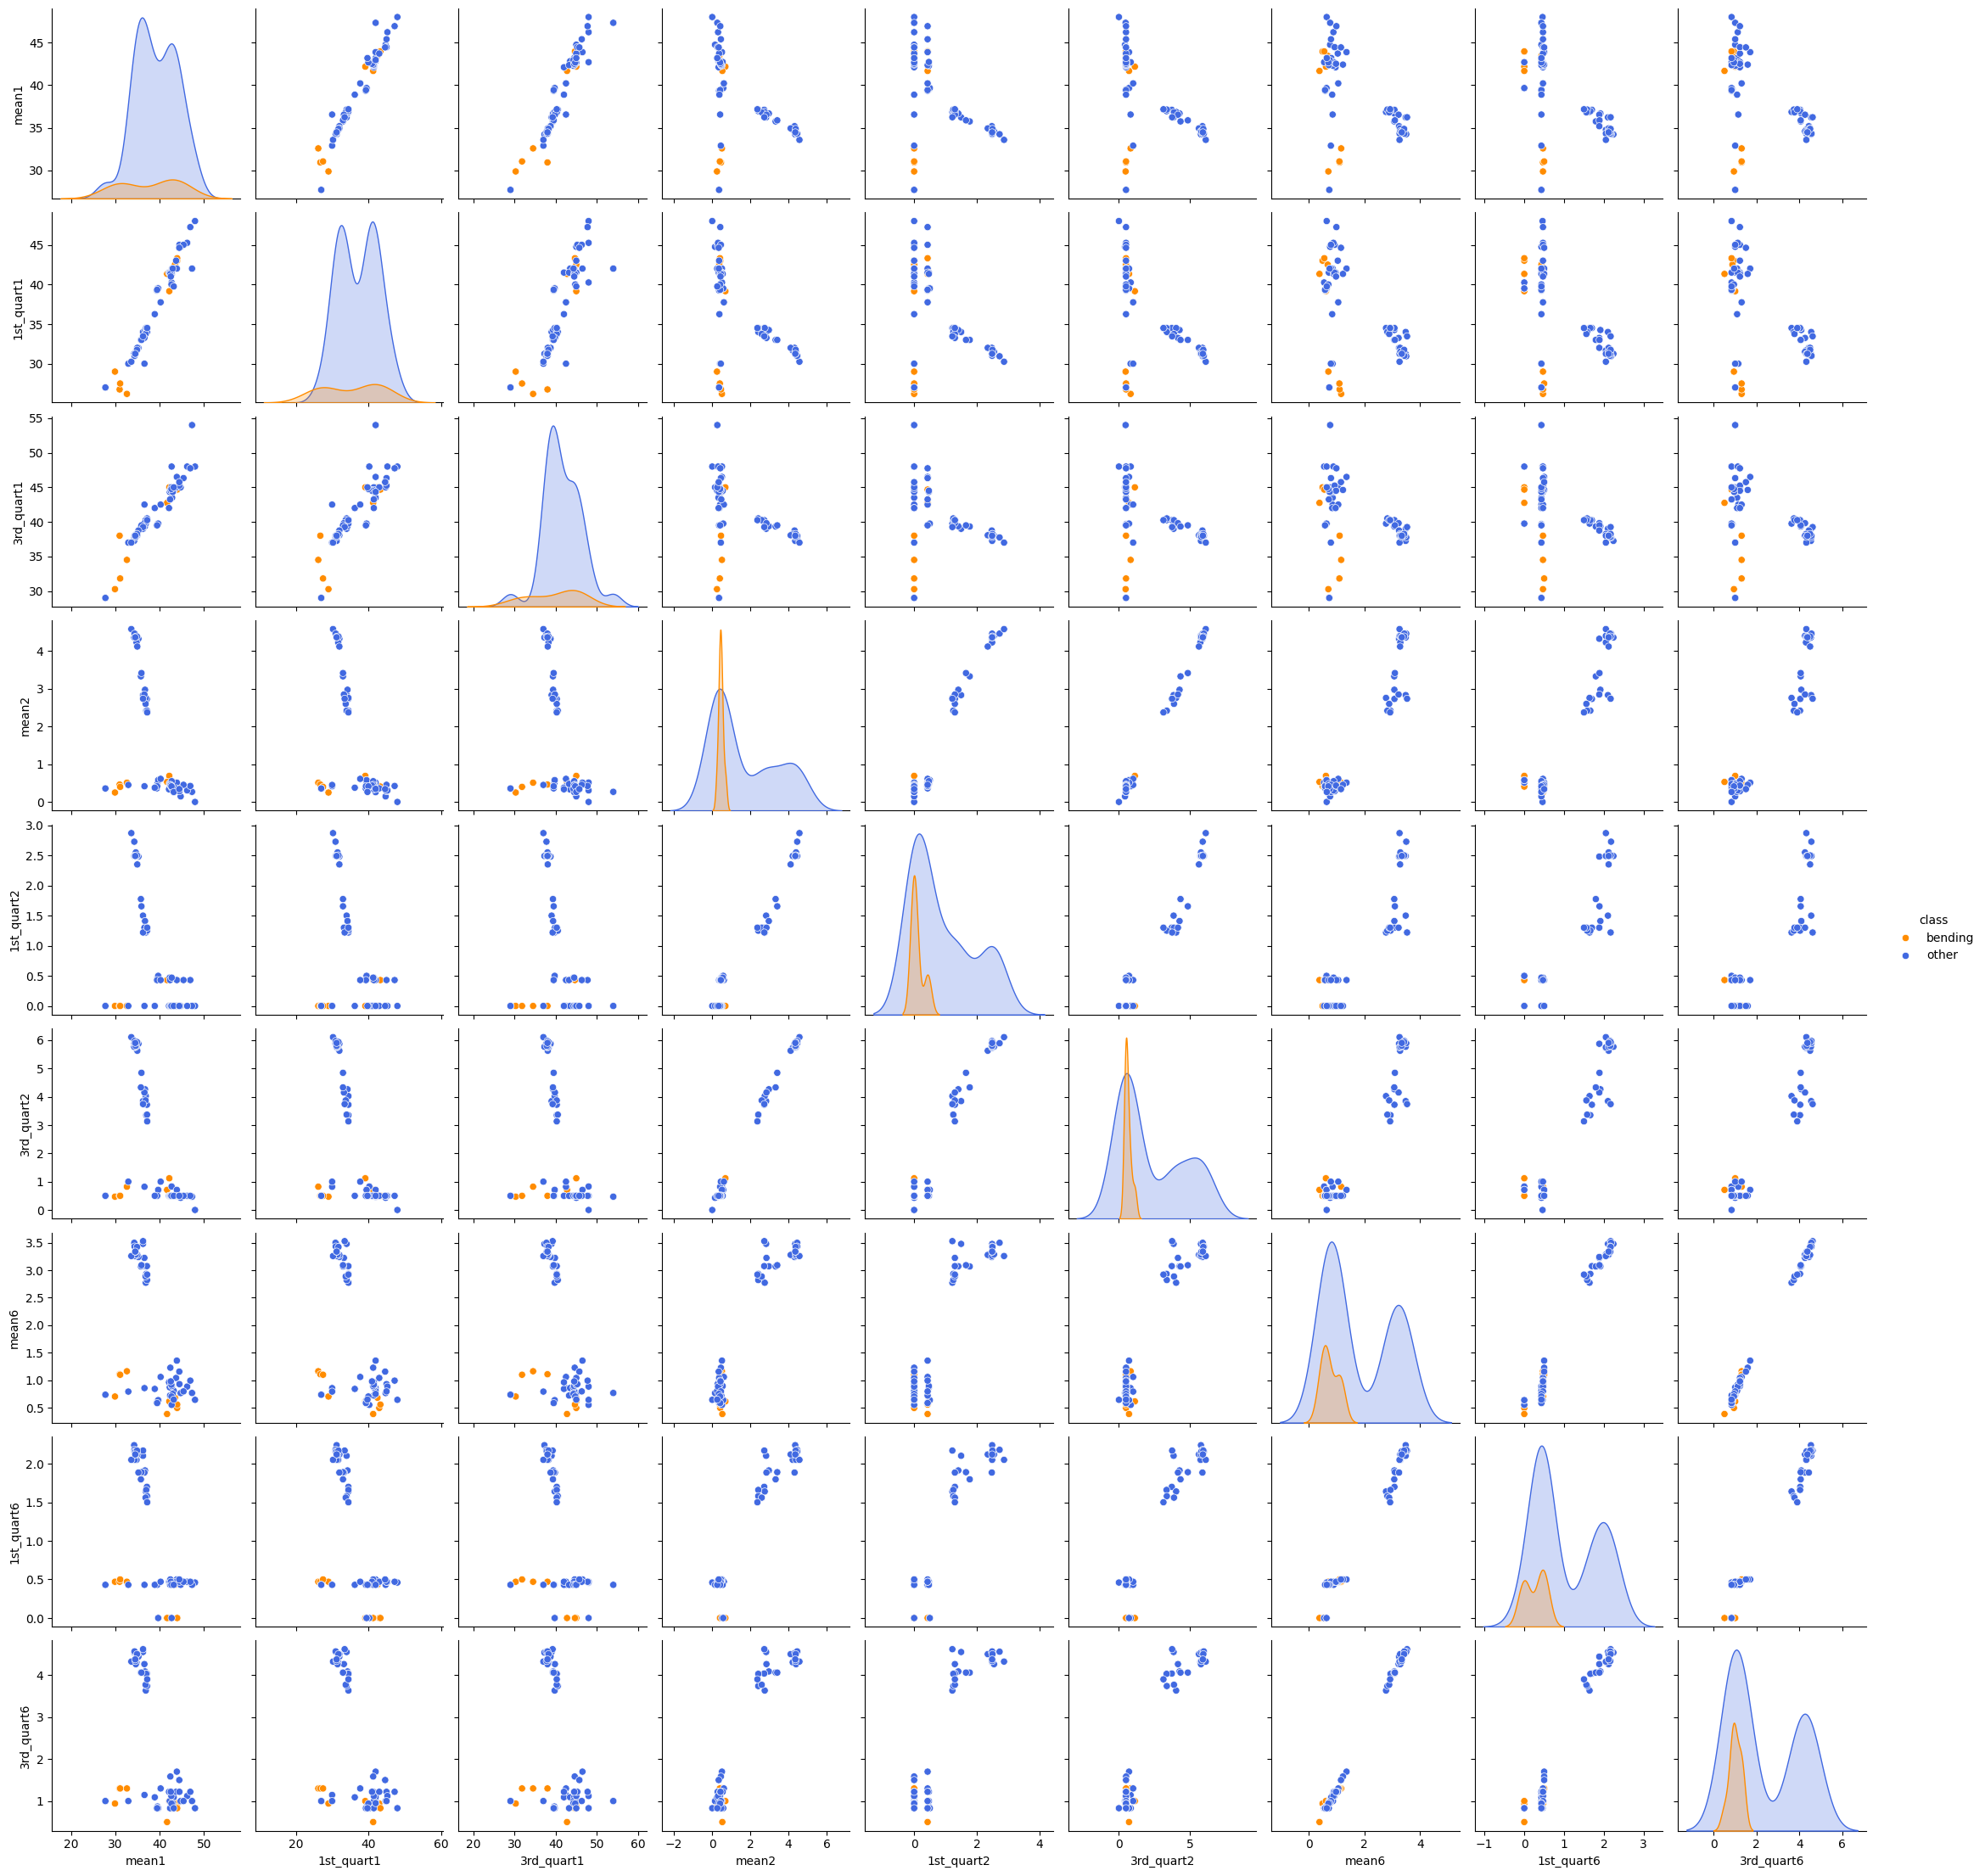

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt

train_keys = [(act, i) for act, i, df in train]
train_features = features[[(a, d) in train_keys for a, d in zip(features["activity"], features["dataset"])]].copy()
train_features["class"] = np.where(train_features["activity"].str.startswith("bending"), "bending", "other")

selected = ["mean1", "1st_quart1", "3rd_quart1", "mean2", "1st_quart2", "3rd_quart2", "mean6", "1st_quart6", "3rd_quart6"]
print(train_features["class"].value_counts())
sns.pairplot(train_features, vars=selected, hue="class", palette={"bending": "darkorange", "other": "royalblue"})
plt.show()

### a (ii)

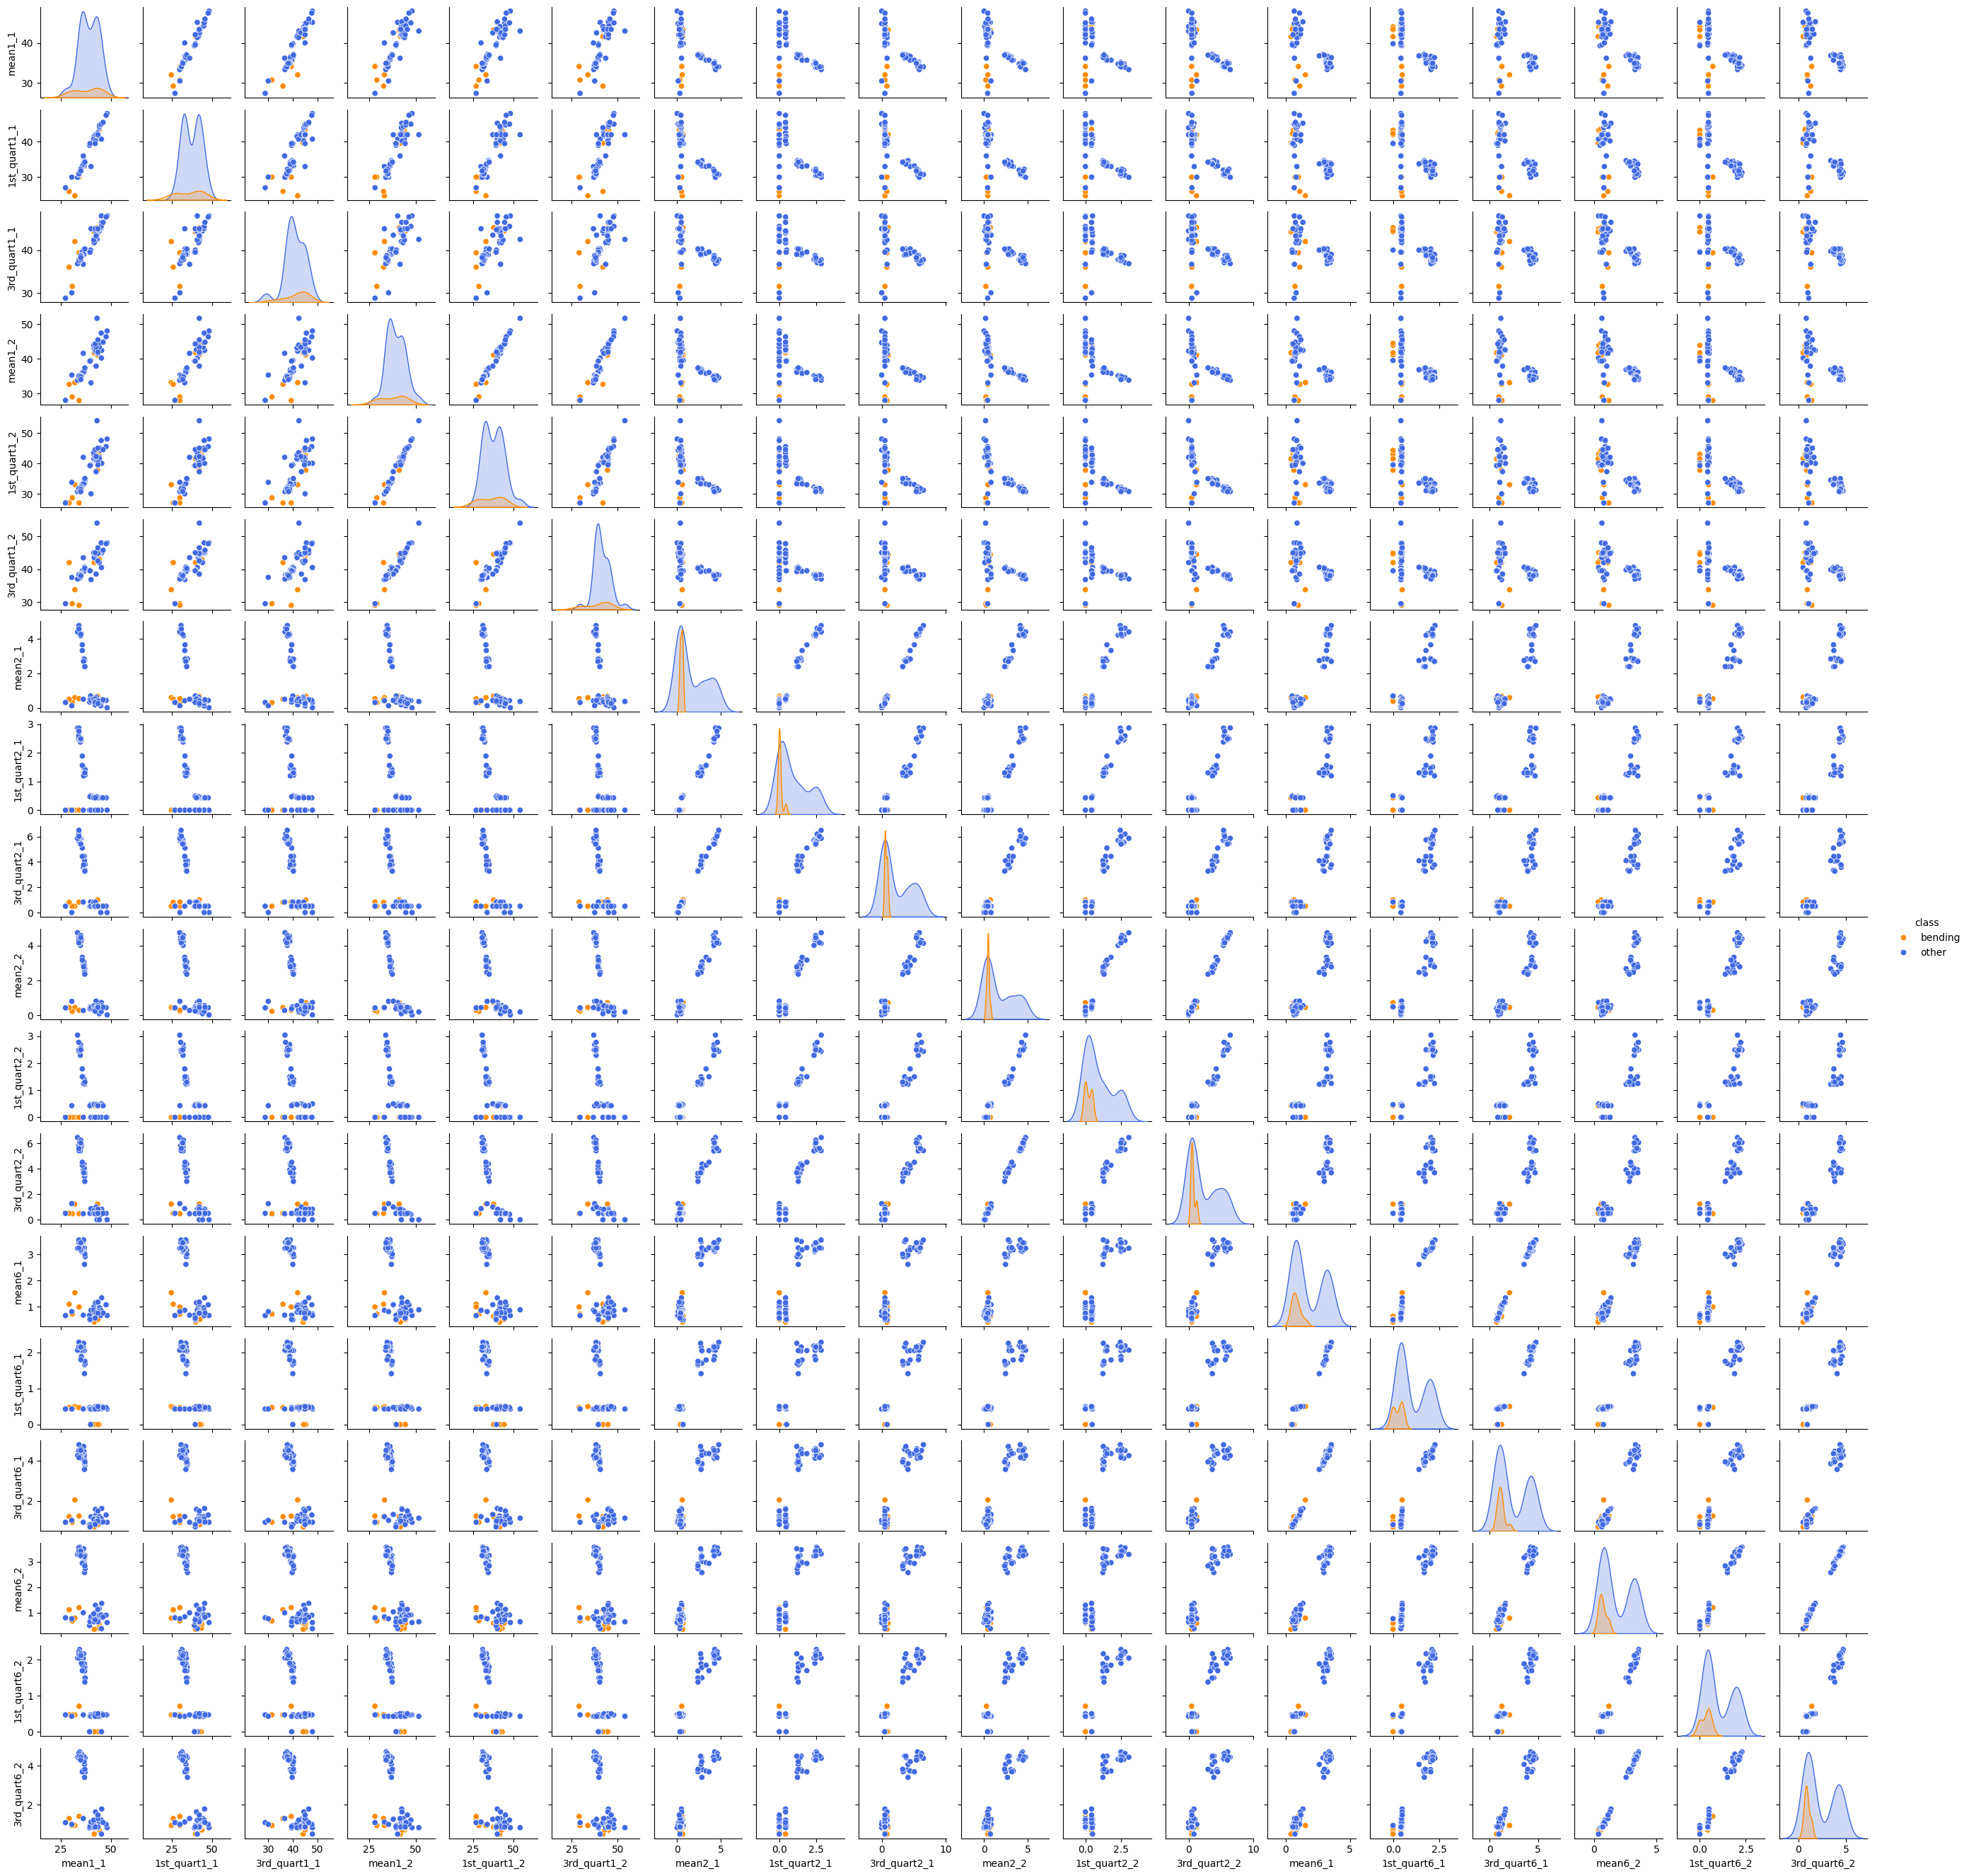

In [7]:
def extract_features(instances, number_of_parts):
    rows = []
    
    for activity, dataset_number, dataframe in instances:
        row = {"activity": activity, "dataset": dataset_number}
        
        for series_number, column in enumerate(cols[1:], 1):
            series_parts = np.array_split(dataframe[column].values, number_of_parts)
            
            for part_number, part_values in enumerate(series_parts, 1):
                part_values = pd.Series(part_values)
                
                row[f"min{series_number}_{part_number}"] = part_values.min()
                row[f"max{series_number}_{part_number}"] = part_values.max()
                row[f"mean{series_number}_{part_number}"] = part_values.mean()
                row[f"median{series_number}_{part_number}"] = part_values.median()
                row[f"std{series_number}_{part_number}"] = part_values.std()
                
                row[f"1st_quart{series_number}_{part_number}"] = part_values.quantile(0.25)
                row[f"3rd_quart{series_number}_{part_number}"] = part_values.quantile(0.75)
                
        rows.append(row)
    return pd.DataFrame(rows)


train_features_two_parts = extract_features(train, 2)
train_features_two_parts["class"] = np.where(train_features_two_parts["activity"].str.startswith("bending"), "bending", "other")
selected_two_parts = ["mean1_1", "1st_quart1_1", "3rd_quart1_1", "mean1_2", "1st_quart1_2", "3rd_quart1_2", "mean2_1", "1st_quart2_1", "3rd_quart2_1", "mean2_2", "1st_quart2_2", "3rd_quart2_2", "mean6_1", "1st_quart6_1", "3rd_quart6_1", "mean6_2", "1st_quart6_2", "3rd_quart6_2"]
sns.pairplot(train_features_two_parts, vars=selected_two_parts, hue="class", palette={"bending": "darkorange", "other": "royalblue"}, height=1.5)
plt.show()

There is not much considerable difference here compared to the results of 2(a)i. The features from the two halves of each series are strongly correlated, for example, mean1_1 and mean1_2 lie close to a straight line. Therefore, splitting here mostly duplicates the information already present. Bending is still separated very clearly from the activities with high values in series 2 and 6, but there is still overlapping with the low-variance activities in most of the plots.

### a (iii)

In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import RFE
from sklearn.model_selection import StratifiedKFold


train_labels = []
for activity, dataset_number, dataframe in train:
    if activity.startswith("bending"):
        train_labels.append(1)
    else:
        train_labels.append(0)
train_labels = np.array(train_labels)

stratified_folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
max_number_of_features = 20

cross_validation_results = []

for number_of_parts in range(1, 21):
    train_feature_matrix = extract_features(train, number_of_parts).drop(columns=["activity", "dataset"]).values
    fold_accuracies = np.zeros((5, max_number_of_features))
    
    for fold_number, (training_indices, validation_indices) in enumerate(stratified_folds.split(train_feature_matrix, train_labels)):
        standard_scaler = StandardScaler().fit(train_feature_matrix[training_indices])
        fold_training_features = standard_scaler.transform(train_feature_matrix[training_indices])
        fold_validation_features = standard_scaler.transform(train_feature_matrix[validation_indices])
        
        feature_eliminator = RFE(LogisticRegression(C=1e10), n_features_to_select=1).fit(fold_training_features, train_labels[training_indices])
        
        for number_of_features in range(1, max_number_of_features + 1):
            selected_columns = feature_eliminator.ranking_ <= number_of_features
            
            logistic_model = LogisticRegression(C=1e10).fit(fold_training_features[:, selected_columns], train_labels[training_indices])
            fold_accuracies[fold_number, number_of_features - 1] = logistic_model.score(fold_validation_features[:, selected_columns], train_labels[validation_indices])
            
    for number_of_features in range(1, max_number_of_features + 1):
        cross_validation_results.append([number_of_parts, number_of_features, fold_accuracies[:, number_of_features - 1].mean()])


cross_validation_results = pd.DataFrame(cross_validation_results, columns=["l", "p", "CV Accuracy"])
best_cross_validation_result = cross_validation_results.loc[cross_validation_results["CV Accuracy"].idxmax()]

best_number_of_parts = int(best_cross_validation_result["l"])
best_number_of_features = int(best_cross_validation_result["p"])


print("best l:", best_number_of_parts)
print("best p:", best_number_of_features)
print("best CV accuracy:", best_cross_validation_result["CV Accuracy"])
cross_validation_results.pivot(index="l", columns="p", values="CV Accuracy").round(3)

best l: 1
best p: 12
best CV accuracy: 0.9857142857142858


p,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
l,,,,,,,,,,,,,,,,,,,,
1,0.943,0.941,0.970,0.955,0.941,0.971,0.957,0.957,0.957,0.956,0.971,0.986,0.971,0.971,0.971,0.971,0.971,0.971,0.971,0.971
2,0.913,0.913,0.957,0.971,0.986,0.956,0.942,0.956,0.942,0.942,0.957,0.957,0.957,0.957,0.943,0.943,0.943,0.927,0.943,0.943
3,0.927,0.927,0.927,0.942,0.942,0.927,0.913,0.913,0.927,0.927,0.913,0.913,0.899,0.899,0.927,0.913,0.899,0.899,0.899,0.899
4,0.956,0.926,0.927,0.913,0.913,0.913,0.899,0.899,0.899,0.899,0.899,0.899,0.913,0.927,0.899,0.927,0.913,0.899,0.913,0.913
5,0.927,0.927,0.913,0.913,0.856,0.856,0.856,0.899,0.899,0.885,0.885,0.870,0.870,0.885,0.885,0.899,0.913,0.913,0.913,0.899
6,0.897,0.926,0.926,0.955,0.941,0.912,0.956,0.956,0.942,0.942,0.942,0.942,0.942,0.942,0.942,0.942,0.927,0.942,0.942,0.927
7,0.913,0.882,0.911,0.926,0.927,0.942,0.942,0.927,0.927,0.927,0.927,0.913,0.899,0.899,0.913,0.899,0.913,0.899,0.899,0.899
8,0.899,0.927,0.941,0.912,0.898,0.898,0.898,0.869,0.855,0.899,0.884,0.899,0.899,0.885,0.885,0.885,0.899,0.899,0.899,0.899
9,0.913,0.912,0.882,0.882,0.912,0.912,0.926,0.912,0.898,0.898,0.898,0.898,0.898,0.913,0.913,0.913,0.885,0.885,0.899,0.899


In [9]:
cross_validation_results[cross_validation_results["CV Accuracy"] == cross_validation_results["CV Accuracy"].max()]

,l,p,CV Accuracy
11,1,12,0.985714
24,2,5,0.985714


The best pair found by 5-fold stratified cross-validation is l = 1 and p = 12, which has a CV accuracy of 0.986. The pair l = 2 and p = 5 also reached 0.986. Since both of them give the same accuracy here, the pair with the smaller l was chosen, as l = 1 does not split the time series and gives fewer features to select from.

The wrong way here would be to run feature selection on the whole training set first and then cross-validate only the logistic regression on the kept features. Because the validation folds already influenced the selection, the CV accuracy would become too optimistic. The right way, which I used here, is to repeat standardization and RFE inside every fold using only that fold’s training data, so each (l, p) pair is scored on data it never saw during selection.

Stratified cross-validation keeps approximately the same class proportions in every fold. Since only 9 of the 69 training instances are bending, a random split could leave a fold with few or no bending cases, which is why I used StratifiedKFold.

### a (iv)

In [10]:
%pip install --upgrade statsmodels

Note: you may need to restart the kernel to use updated packages.


Selected features: ['min1_1', 'max1_1', '3rd_quart1_1', 'max2_1', '3rd_quart3_1', 'max4_1', '1st_quart4_1', 'min5_1', 'max5_1', 'mean5_1', 'std6_1', '1st_quart6_1']

Confusion matrix on train data:
                Predicted other  Predicted bending
Actual other                 60                  0
Actual bending                0                  9

AUC on train data: 1.0


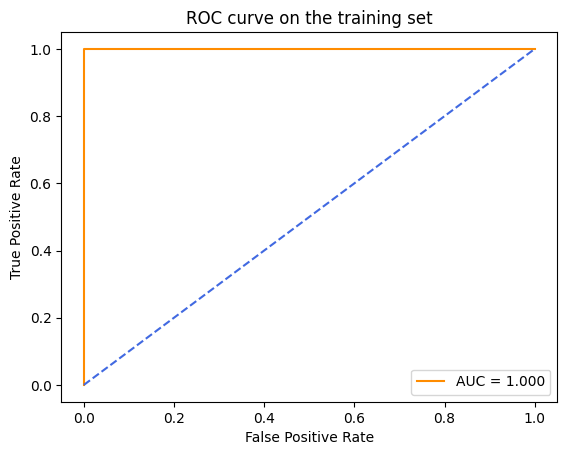

C:\Users\mujah\miniconda3\Lib\site-packages\statsmodels\base\optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
C:\Users\mujah\miniconda3\Lib\site-packages\statsmodels\base\optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
C:\Users\mujah\miniconda3\Lib\site-packages\statsmodels\base\optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
C:\Users\mujah\miniconda3\Lib\site-packages\statsmodels\base\optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
C:\Users\mujah\miniconda3\Lib\site-packages\statsmodels\base\optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(n

,sklearn Coefficient,statsmodels Coefficient,p-value
intercept,-10.304878,-29.088080,0.999408
min1_1,-2.259826,-7.211185,0.999905
max1_1,1.563863,8.325641,0.999917
3rd_quart1_1,-3.513277,-12.906336,0.999898
max2_1,-1.947357,-10.236443,0.999898
3rd_quart3_1,-1.445773,-0.808941,0.999990
max4_1,2.328499,8.586997,0.999903
1st_quart4_1,-1.994738,-8.125004,0.999967
min5_1,4.775560,19.876190,0.999835
max5_1,4.539330,9.630232,0.999924


In [11]:
import statsmodels.api as sm
from sklearn.metrics import confusion_matrix
from sklearn.metrics import roc_auc_score
from sklearn.metrics import roc_curve

train_features_best = extract_features(train, best_number_of_parts).drop(columns=["activity", "dataset"])
final_standard_scaler = StandardScaler().fit(train_features_best.values)
train_features_scaled = final_standard_scaler.transform(train_features_best.values)
final_feature_eliminator = RFE(LogisticRegression(C=1e10), n_features_to_select=best_number_of_features).fit(train_features_scaled, train_labels)
selected_feature_names = list(train_features_best.columns[final_feature_eliminator.support_])
train_selected_features = train_features_scaled[:, final_feature_eliminator.support_]
final_logistic_model = LogisticRegression(C=1e10).fit(train_selected_features, train_labels)
train_predictions = final_logistic_model.predict(train_selected_features)
train_probabilities = final_logistic_model.predict_proba(train_selected_features)[:, 1]


print("Selected features:", selected_feature_names)
print()

print("Confusion matrix on train data:")
print(pd.DataFrame(confusion_matrix(train_labels, train_predictions), index=["Actual other", "Actual bending"], columns=["Predicted other", "Predicted bending"]))

false_positive_rate, true_positive_rate, roc_thresholds = roc_curve(train_labels, train_probabilities)
train_auc = roc_auc_score(train_labels, train_probabilities)

print()
print("AUC on train data:", train_auc)
plt.plot(false_positive_rate, true_positive_rate, color="darkorange", label=f"AUC = {train_auc:.3f}")
plt.plot([0, 1], [0, 1], color="royalblue", linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC curve on the training set")
plt.legend()
plt.show()

statsmodels_logistic_model = sm.Logit(train_labels, sm.add_constant(train_selected_features)).fit(disp=0)
coefficient_table = pd.DataFrame({"sklearn Coefficient": np.r_[final_logistic_model.intercept_, final_logistic_model.coef_[0]], "statsmodels Coefficient": statsmodels_logistic_model.params, "p-value": statsmodels_logistic_model.pvalues}, index=["intercept"] + selected_feature_names)

coefficient_table

### a (v)

In [12]:
test_labels = []

for activity, dataset_number, dataframe in test:
    
    if activity in ("bending1", "bending2"):
        test_labels.append(1)
    else:
        test_labels.append(0)

        
test_labels = np.array(test_labels)
test_features_best = extract_features(test, best_number_of_parts).drop(columns=["activity", "dataset"])
test_features_scaled = final_standard_scaler.transform(test_features_best.values)
test_selected_features = test_features_scaled[:, final_feature_eliminator.support_]
test_predictions = final_logistic_model.predict(test_selected_features)
test_accuracy = final_logistic_model.score(test_selected_features, test_labels)

print("Confusion matrix on test data:")
print(pd.DataFrame(confusion_matrix(test_labels, test_predictions), index=["Actual other", "Actual bending"], columns=["Predicted other", "Predicted bending"]))

print()

print("Test accuracy:", test_accuracy)
print("Cross-validation accuracy:", best_cross_validation_result["CV Accuracy"])

Confusion matrix on test data:
                Predicted other  Predicted bending
Actual other                 15                  0
Actual bending                0                  4

Test accuracy: 1.0
Cross-validation accuracy: 0.9857142857142858


The test accuracy achieved here is 1.0 and the cross-validation accuracy is 0.986, so they are very close. Therefore, this means the cross-validation accuracy was a good prediction of how well the model would do on new data.

### a (vi)

Yes, the classes here are well separated enough to cause instability. The model classifies all training instances correctly with an AUC of 1.0, which means a boundary exists that perfectly separates bending from the other activities. When this happens, the likelihood keeps increasing as the coefficients grow larger, which leads us to conclude that there is no finite best estimate. This is properly shown by the PerfectSeparationWarning and the failed convergence from statsmodels, and also by the p-values of all coefficients being close to 1 because their standard errors became very large. Therefore, the coefficient values depend on when the optimizer stops and cannot be trusted, even though the predictions themselves are still accurate.

### a (vii)

Yes, the classes here are imbalanced. The training set has 60 other instances and only 9 bending instances, and the test set has 15 other and 4 bending. A logistic regression model based on case-control sampling is needed to be built and it is given below.

Case-control sample size: 18 with 9 bending
Adjusted intercept: -7.668037294132752

Confusion matrix on the training set:
                Predicted other  Predicted bending
Actual other                 60                  0
Actual bending                0                  9
AUC on the training set: 0.9999999999999999

Confusion matrix on the test set:
                Predicted other  Predicted bending
Actual other                 15                  0
Actual bending                0                  4
AUC on the test set: 1.0


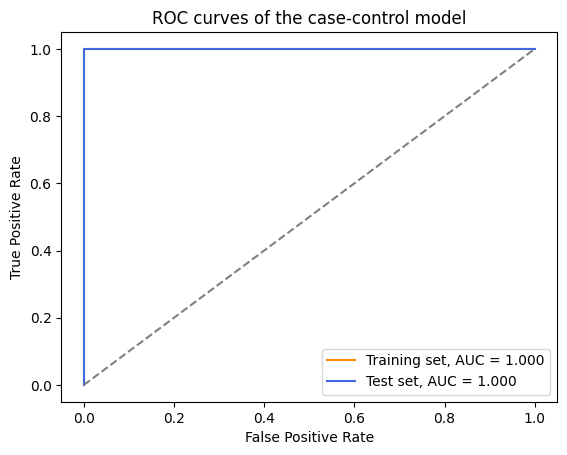

In [13]:
random_generator_case_control = np.random.default_rng(0)

bending_indices = np.where(train_labels == 1)[0]
other_indices = np.where(train_labels == 0)[0]
sampled_other_indices = random_generator_case_control.choice(other_indices, size=len(bending_indices), replace=False)
case_control_indices = np.concatenate([bending_indices, sampled_other_indices])
case_control_features = train_selected_features[case_control_indices]
case_control_labels = train_labels[case_control_indices]
case_control_model = LogisticRegression(C=1e10).fit(case_control_features, case_control_labels)


true_bending_fraction = train_labels.mean()
sample_bending_fraction = case_control_labels.mean()
true_log_odds = np.log(true_bending_fraction / (1 - true_bending_fraction))
sample_log_odds = np.log(sample_bending_fraction / (1 - sample_bending_fraction))
case_control_model.intercept_ = case_control_model.intercept_ + true_log_odds - sample_log_odds

print("Case-control sample size:", len(case_control_labels), "with", case_control_labels.sum(), "bending")
print("Adjusted intercept:", case_control_model.intercept_[0])


case_control_train_predictions = case_control_model.predict(train_selected_features)
case_control_train_probabilities = case_control_model.predict_proba(train_selected_features)[:, 1]
case_control_train_auc = roc_auc_score(train_labels, case_control_train_probabilities)

print()
print("Confusion matrix on the training set:")
print(pd.DataFrame(confusion_matrix(train_labels, case_control_train_predictions), index=["Actual other", "Actual bending"], columns=["Predicted other", "Predicted bending"]))
print("AUC on the training set:", case_control_train_auc)

case_control_test_predictions = case_control_model.predict(test_selected_features)
case_control_test_probabilities = case_control_model.predict_proba(test_selected_features)[:, 1]
case_control_test_auc = roc_auc_score(test_labels, case_control_test_probabilities)

print()
print("Confusion matrix on the test set:")
print(pd.DataFrame(confusion_matrix(test_labels, case_control_test_predictions), index=["Actual other", "Actual bending"], columns=["Predicted other", "Predicted bending"]))
print("AUC on the test set:", case_control_test_auc)


train_false_positive_rate, train_true_positive_rate, train_thresholds = roc_curve(train_labels, case_control_train_probabilities)
test_false_positive_rate, test_true_positive_rate, test_thresholds = roc_curve(test_labels, case_control_test_probabilities)

plt.plot(train_false_positive_rate, train_true_positive_rate, color="darkorange", label=f"Training set, AUC = {case_control_train_auc:.3f}")
plt.plot(test_false_positive_rate, test_true_positive_rate, color="royalblue", label=f"Test set, AUC = {case_control_test_auc:.3f}")
plt.plot([0, 1], [0, 1], color="gray", linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC curves of the case-control model")
plt.legend()

plt.show()

### b (i)

In [14]:
penalty_budget_values = np.logspace(-4, 4, 10)

l1_cross_validation_results = []
for number_of_parts in range(1, 21):
    
    train_feature_matrix = extract_features(train, number_of_parts).drop(columns=["activity", "dataset"]).values
    
    for penalty_budget in penalty_budget_values:
        
        fold_accuracies = []
        for training_indices, validation_indices in stratified_folds.split(train_feature_matrix, train_labels):
            
            standard_scaler = StandardScaler().fit(train_feature_matrix[training_indices])
            fold_training_features = standard_scaler.transform(train_feature_matrix[training_indices])
            fold_validation_features = standard_scaler.transform(train_feature_matrix[validation_indices])
            l1_logistic_model = LogisticRegression(penalty="l1", solver="liblinear", C=penalty_budget, random_state=0).fit(fold_training_features, train_labels[training_indices])
            fold_accuracies.append(l1_logistic_model.score(fold_validation_features, train_labels[validation_indices]))
            
        l1_cross_validation_results.append([number_of_parts, penalty_budget, np.mean(fold_accuracies)])


l1_cross_validation_results = pd.DataFrame(l1_cross_validation_results, columns=["l", "C", "CV Accuracy"])
best_l1_result = l1_cross_validation_results.loc[l1_cross_validation_results["CV Accuracy"].idxmax()]
best_l1_number_of_parts = int(best_l1_result["l"])
best_l1_penalty_budget = best_l1_result["C"]
print("Best l:", best_l1_number_of_parts)
print("Best C:", best_l1_penalty_budget)
print("Best CV accuracy:", best_l1_result["CV Accuracy"])


l1_accuracy_table = l1_cross_validation_results.pivot(index="l", columns="C", values="CV Accuracy").round(3)
l1_accuracy_table.columns = l1_accuracy_table.columns.round(4)

l1_accuracy_table

Best l: 1
Best C: 2.782559402207126
Best CV accuracy: 0.9857142857142858


C,0.0001,0.0008,0.0060,0.0464,0.3594,2.7826,21.5443,166.8101,1291.5497,10000.0000
l,,,,,,,,,,
1,0.87,0.87,0.87,0.87,0.970,0.986,0.971,0.971,0.971,0.971
2,0.87,0.87,0.87,0.87,0.957,0.957,0.971,0.971,0.957,0.927
3,0.87,0.87,0.87,0.87,0.971,0.957,0.942,0.927,0.927,0.927
4,0.87,0.87,0.87,0.87,0.943,0.913,0.899,0.899,0.885,0.913
5,0.87,0.87,0.87,0.87,0.912,0.927,0.898,0.898,0.913,0.913
6,0.87,0.87,0.87,0.87,0.912,0.926,0.942,0.942,0.942,0.970
7,0.87,0.87,0.87,0.87,0.927,0.912,0.927,0.942,0.912,0.885
8,0.87,0.87,0.87,0.87,0.927,0.927,0.927,0.913,0.927,0.942
9,0.87,0.87,0.87,0.87,0.927,0.926,0.912,0.927,0.927,0.927


In [15]:
l1_train_features = extract_features(train, best_l1_number_of_parts).drop(columns=["activity", "dataset"])
l1_test_features = extract_features(test, best_l1_number_of_parts).drop(columns=["activity", "dataset"])
l1_standard_scaler = StandardScaler().fit(l1_train_features.values)
l1_train_features_scaled = l1_standard_scaler.transform(l1_train_features.values)
l1_test_features_scaled = l1_standard_scaler.transform(l1_test_features.values)
final_l1_logistic_model = LogisticRegression(penalty="l1", solver="liblinear", C=best_l1_penalty_budget, random_state=0).fit(l1_train_features_scaled, train_labels)
l1_test_predictions = final_l1_logistic_model.predict(l1_test_features_scaled)
l1_test_accuracy = final_l1_logistic_model.score(l1_test_features_scaled, test_labels)

print("Confusion matrix on test data:")
print(pd.DataFrame(confusion_matrix(test_labels, l1_test_predictions), index=["Actual other", "Actual bending"], columns=["Predicted other", "Predicted bending"]))

print()

print("Test accuracy:", l1_test_accuracy)
print("Cross-validation accuracy:", best_l1_result["CV Accuracy"])

l1_coefficients = pd.DataFrame({"Coefficient": final_l1_logistic_model.coef_[0]}, index=l1_train_features.columns)
l1_nonzero_coefficients = l1_coefficients[l1_coefficients["Coefficient"]!=0]

print()

print("Number of features with nonzero coefficients:", len(l1_nonzero_coefficients))

l1_nonzero_coefficients

Confusion matrix on test data:
                Predicted other  Predicted bending
Actual other                 15                  0
Actual bending                0                  4

Test accuracy: 1.0
Cross-validation accuracy: 0.9857142857142858

Number of features with nonzero coefficients: 8


,Coefficient
3rd_quart1_1,-0.773337
max2_1,-0.173968
1st_quart3_1,-0.562989
1st_quart4_1,-0.408269
min5_1,1.864233
max5_1,2.612198
1st_quart5_1,0.127446
1st_quart6_1,-0.533311


### b (ii)

Both methods here chose l = 1, reached a cross-validation accuracy of 0.986, and classified every test instance correctly, so they performed equally if we look at it in terms of accuracy. The L1-penalized model is still the better choice here, since it used only 8 features compared to 12 with RFE, which I used in place of p-value pruning, and its coefficients stayed stable. With RFE, perfect separation caused the coefficients to become extremely large and pushed all p-values close to 1, so they were not useful for selecting features. L1 is also easier to implement, because the penalty performs feature selection during fitting and only C needs to be tuned here. RFE required a separate elimination step and statsmodels to obtain the p-values.

### c (i)

In [16]:
train_activity_labels = []

for activity, dataset_number, dataframe in train:
    train_activity_labels.append(activity)
    
train_activity_labels = np.array(train_activity_labels)

multinomial_cross_validation_results = []
for number_of_parts in range(1, 21):
    
    train_feature_matrix = extract_features(train, number_of_parts).drop(columns=["activity", "dataset"]).values
    
    for penalty_budget in penalty_budget_values:
        
        fold_accuracies = []
        for training_indices, validation_indices in stratified_folds.split(train_feature_matrix, train_activity_labels):
            
            standard_scaler = StandardScaler().fit(train_feature_matrix[training_indices])
            fold_training_features = standard_scaler.transform(train_feature_matrix[training_indices])
            fold_validation_features = standard_scaler.transform(train_feature_matrix[validation_indices])
            multinomial_model = LogisticRegression(penalty="l1", solver="saga", C=penalty_budget, max_iter=1000, random_state=0).fit(fold_training_features, train_activity_labels[training_indices])
            fold_accuracies.append(multinomial_model.score(fold_validation_features, train_activity_labels[validation_indices]))
            
        multinomial_cross_validation_results.append([number_of_parts, penalty_budget, np.mean(fold_accuracies)])


multinomial_cross_validation_results = pd.DataFrame(multinomial_cross_validation_results, columns=["l", "C", "CV Accuracy"])
best_multinomial_result = multinomial_cross_validation_results.loc[multinomial_cross_validation_results["CV Accuracy"].idxmax()]
best_multinomial_number_of_parts = int(best_multinomial_result["l"])
best_multinomial_penalty_budget = best_multinomial_result["C"]
print("Best l:", best_multinomial_number_of_parts)
print("Best C:", best_multinomial_penalty_budget)
print("Best CV accuracy:", best_multinomial_result["CV Accuracy"])

multinomial_accuracy_table = multinomial_cross_validation_results.pivot(index="l", columns="C", values="CV Accuracy").round(3)
multinomial_accuracy_table.columns = multinomial_accuracy_table.columns.round(4)

multinomial_accuracy_table

C:\Users\mujah\AppData\Roaming\Python\Python313\site-packages\sklearn\model_selection\_split.py:811: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
C:\Users\mujah\AppData\Roaming\Python\Python313\site-packages\sklearn\model_selection\_split.py:811: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
C:\Users\mujah\AppData\Roaming\Python\Python313\site-packages\sklearn\model_selection\_split.py:811: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
C:\Users\mujah\AppData\Roaming\Python\Python313\site-packages\sklearn\model_selection\_split.py:811: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
C:\Users\mujah\AppData\Roaming\Python\Python313\site-packages\sklearn\model_selection\_split.py:811: UserWarning: The least populated class in y has

Best l: 1
Best C: 2.782559402207126
Best CV accuracy: 0.9120879120879121


C:\Users\mujah\AppData\Roaming\Python\Python313\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


C,0.0001,0.0008,0.0060,0.0464,0.3594,2.7826,21.5443,166.8101,1291.5497,10000.0000
l,,,,,,,,,,
1,0.189,0.189,0.189,0.145,0.796,0.912,0.884,0.884,0.884,0.884
2,0.189,0.189,0.175,0.145,0.854,0.854,0.868,0.854,0.868,0.868
3,0.189,0.189,0.175,0.145,0.753,0.825,0.825,0.826,0.826,0.826
4,0.189,0.189,0.175,0.145,0.767,0.782,0.811,0.812,0.826,0.826
5,0.189,0.189,0.175,0.145,0.753,0.782,0.840,0.840,0.825,0.825
6,0.189,0.189,0.175,0.145,0.738,0.838,0.838,0.824,0.824,0.824
7,0.189,0.189,0.175,0.145,0.738,0.767,0.825,0.854,0.854,0.854
8,0.189,0.189,0.175,0.145,0.796,0.796,0.767,0.810,0.825,0.825
9,0.189,0.189,0.175,0.145,0.780,0.780,0.795,0.825,0.825,0.825


In multiclass classification, the confusion matrix becomes KxK, so 7x7 here, with the actual class as rows and the predicted class as columns. Correct predictions here fall on the diagonal, and every other entry shows how many instances of one activity were misclassified as another. Since ROC curves are only defined for two classes, the one-vs-rest approach is used here, where each activity is treated as positive and all others as negative. This results in a separate ROC curve and AUC for every activity.

Test error: 0.10526315789473684

Confusion matrix on test data, actual vs predicted:
          bending1  bending2  cycling  lying  sitting  standing  walking
bending1         2         0        0      0        0         0        0
bending2         0         2        0      0        0         0        0
cycling          0         0        3      0        0         0        0
lying            0         0        0      3        0         0        0
sitting          0         0        0      0        2         1        0
standing         0         0        0      1        0         2        0
walking          0         0        0      0        0         0        3

Macro-average AUC on test data: 0.9940476190476192


C:\Users\mujah\AppData\Roaming\Python\Python313\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


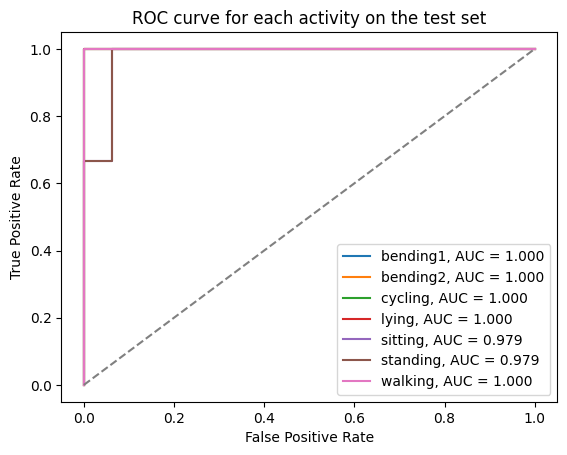

In [17]:
from sklearn.preprocessing import label_binarize

test_activity_labels = []
for activity, dataset_number, dataframe in test:
    
    test_activity_labels.append(activity)
    
test_activity_labels = np.array(test_activity_labels)


multinomial_train_features = extract_features(train, best_multinomial_number_of_parts).drop(columns=["activity", "dataset"])
multinomial_test_features = extract_features(test, best_multinomial_number_of_parts).drop(columns=["activity", "dataset"])
multinomial_standard_scaler = StandardScaler().fit(multinomial_train_features.values)
multinomial_train_features_scaled = multinomial_standard_scaler.transform(multinomial_train_features.values)
multinomial_test_features_scaled = multinomial_standard_scaler.transform(multinomial_test_features.values)
final_multinomial_model = LogisticRegression(penalty="l1", solver="saga", C=best_multinomial_penalty_budget, max_iter=1000, random_state=0).fit(multinomial_train_features_scaled, train_activity_labels)
multinomial_test_predictions = final_multinomial_model.predict(multinomial_test_features_scaled)
multinomial_test_error = 1 - final_multinomial_model.score(multinomial_test_features_scaled, test_activity_labels)
activity_classes = final_multinomial_model.classes_


print("Test error:", multinomial_test_error)

print()
print("Confusion matrix on test data, actual vs predicted:")
print(pd.DataFrame(confusion_matrix(test_activity_labels, multinomial_test_predictions, labels=activity_classes), index=activity_classes, columns=activity_classes))

multinomial_test_probabilities = final_multinomial_model.predict_proba(multinomial_test_features_scaled)
test_labels_binarized = label_binarize(test_activity_labels, classes=activity_classes)
multinomial_macro_auc = roc_auc_score(test_labels_binarized, multinomial_test_probabilities, average="macro")

print()
print("Macro-average AUC on test data:", multinomial_macro_auc)


for class_index, class_name in enumerate(activity_classes):
    false_positive_rate, true_positive_rate, roc_thresholds = roc_curve(test_labels_binarized[:, class_index], multinomial_test_probabilities[:, class_index])
    class_auc = roc_auc_score(test_labels_binarized[:, class_index], multinomial_test_probabilities[:, class_index])
    plt.plot(false_positive_rate, true_positive_rate, label=f"{class_name}, AUC = {class_auc:.3f}")


plt.plot([0, 1], [0, 1], color="gray", linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC curve for each activity on the test set")
plt.legend()

plt.show()

### c (ii)

In [18]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.naive_bayes import GaussianNB


naive_bayes_cross_validation_results = []

for number_of_parts in range(1, 21):
    
    train_feature_matrix = extract_features(train, number_of_parts).drop(columns=["activity", "dataset"]).values
    
    gaussian_fold_accuracies = []
    multinomial_fold_accuracies = []
    for training_indices, validation_indices in stratified_folds.split(train_feature_matrix, train_activity_labels):
        
        gaussian_nb_model = GaussianNB().fit(train_feature_matrix[training_indices], train_activity_labels[training_indices])
        gaussian_fold_accuracies.append(gaussian_nb_model.score(train_feature_matrix[validation_indices], train_activity_labels[validation_indices]))
        multinomial_nb_model = MultinomialNB().fit(train_feature_matrix[training_indices], train_activity_labels[training_indices])
        multinomial_fold_accuracies.append(multinomial_nb_model.score(train_feature_matrix[validation_indices], train_activity_labels[validation_indices]))
        
    naive_bayes_cross_validation_results.append([number_of_parts, np.mean(gaussian_fold_accuracies), np.mean(multinomial_fold_accuracies)])


naive_bayes_cross_validation_results = pd.DataFrame(naive_bayes_cross_validation_results, columns=["l", "Gaussian CV Accuracy", "Multinomial CV Accuracy"])
best_gaussian_number_of_parts = int(naive_bayes_cross_validation_results.loc[naive_bayes_cross_validation_results["Gaussian CV Accuracy"].idxmax(), "l"])
best_multinomial_nb_number_of_parts = int(naive_bayes_cross_validation_results.loc[naive_bayes_cross_validation_results["Multinomial CV Accuracy"].idxmax(), "l"])
print("Best l for Gaussian Naive Bayes:", best_gaussian_number_of_parts, "with CV accuracy", naive_bayes_cross_validation_results["Gaussian CV Accuracy"].max())
print("Best l for Multinomial Naive Bayes:", best_multinomial_nb_number_of_parts, "with CV accuracy", naive_bayes_cross_validation_results["Multinomial CV Accuracy"].max())

naive_bayes_cross_validation_results.round(3)

C:\Users\mujah\AppData\Roaming\Python\Python313\site-packages\sklearn\model_selection\_split.py:811: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
C:\Users\mujah\AppData\Roaming\Python\Python313\site-packages\sklearn\model_selection\_split.py:811: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
C:\Users\mujah\AppData\Roaming\Python\Python313\site-packages\sklearn\model_selection\_split.py:811: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
C:\Users\mujah\AppData\Roaming\Python\Python313\site-packages\sklearn\model_selection\_split.py:811: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
C:\Users\mujah\AppData\Roaming\Python\Python313\site-packages\sklearn\model_selection\_split.py:811: UserWarning: The least populated class in y has

Best l for Gaussian Naive Bayes: 1 with CV accuracy 0.8538461538461538
Best l for Multinomial Naive Bayes: 1 with CV accuracy 0.8549450549450549


C:\Users\mujah\AppData\Roaming\Python\Python313\site-packages\sklearn\model_selection\_split.py:811: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


,l,Gaussian CV Accuracy,Multinomial CV Accuracy
0,1,0.854,0.855
1,2,0.767,0.767
2,3,0.682,0.782
3,4,0.652,0.738
4,5,0.679,0.782
5,6,0.638,0.767
6,7,0.580,0.813
7,8,0.610,0.767
8,9,0.567,0.798
9,10,0.666,0.738


Gaussian Naive Bayes test error: 0.10526315789473684
Confusion matrix on test data, actual vs predicted:
          bending1  bending2  cycling  lying  sitting  standing  walking
bending1         2         0        0      0        0         0        0
bending2         0         2        0      0        0         0        0
cycling          0         0        3      0        0         0        0
lying            0         0        0      2        1         0        0
sitting          0         0        0      0        3         0        0
standing         0         0        0      0        1         2        0
walking          0         0        0      0        0         0        3
Macro-average AUC on test data: 0.9642857142857143

Multinomial Naive Bayes test error: 0.10526315789473684
Confusion matrix on test data, actual vs predicted:
          bending1  bending2  cycling  lying  sitting  standing  walking
bending1         2         0        0      0        0         0        0
bendi

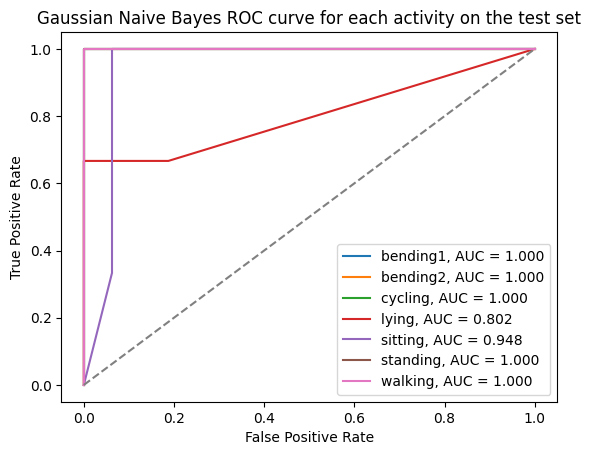

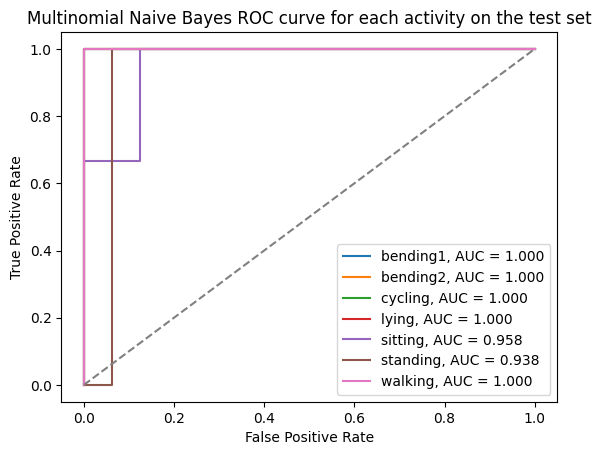

In [19]:
gaussian_nb_train_features = extract_features(train, best_gaussian_number_of_parts).drop(columns=["activity", "dataset"]).values
gaussian_nb_test_features = extract_features(test, best_gaussian_number_of_parts).drop(columns=["activity", "dataset"]).values
final_gaussian_nb_model = GaussianNB().fit(gaussian_nb_train_features, train_activity_labels)
gaussian_nb_test_predictions = final_gaussian_nb_model.predict(gaussian_nb_test_features)
gaussian_nb_test_error = 1 - final_gaussian_nb_model.score(gaussian_nb_test_features, test_activity_labels)
gaussian_nb_test_probabilities = final_gaussian_nb_model.predict_proba(gaussian_nb_test_features)
gaussian_nb_macro_auc = roc_auc_score(test_labels_binarized, gaussian_nb_test_probabilities, average="macro")


multinomial_nb_train_features = extract_features(train, best_multinomial_nb_number_of_parts).drop(columns=["activity", "dataset"]).values
multinomial_nb_test_features = extract_features(test, best_multinomial_nb_number_of_parts).drop(columns=["activity", "dataset"]).values
final_multinomial_nb_model = MultinomialNB().fit(multinomial_nb_train_features, train_activity_labels)
multinomial_nb_test_predictions = final_multinomial_nb_model.predict(multinomial_nb_test_features)
multinomial_nb_test_error = 1 - final_multinomial_nb_model.score(multinomial_nb_test_features, test_activity_labels)
multinomial_nb_test_probabilities = final_multinomial_nb_model.predict_proba(multinomial_nb_test_features)
multinomial_nb_macro_auc = roc_auc_score(test_labels_binarized, multinomial_nb_test_probabilities, average="macro")


print("Gaussian Naive Bayes test error:", gaussian_nb_test_error)
print("Confusion matrix on test data, actual vs predicted:")
print(pd.DataFrame(confusion_matrix(test_activity_labels, gaussian_nb_test_predictions, labels=activity_classes), index=activity_classes, columns=activity_classes))
print("Macro-average AUC on test data:", gaussian_nb_macro_auc)


print()
print("Multinomial Naive Bayes test error:", multinomial_nb_test_error)
print("Confusion matrix on test data, actual vs predicted:")
print(pd.DataFrame(confusion_matrix(test_activity_labels, multinomial_nb_test_predictions, labels=activity_classes), index=activity_classes, columns=activity_classes))
print("Macro-average AUC on test data:", multinomial_nb_macro_auc)

for class_index, class_name in enumerate(activity_classes):
    
    false_positive_rate, true_positive_rate, roc_thresholds = roc_curve(test_labels_binarized[:, class_index], gaussian_nb_test_probabilities[:, class_index])
    class_auc = roc_auc_score(test_labels_binarized[:, class_index], gaussian_nb_test_probabilities[:, class_index])
    plt.plot(false_positive_rate, true_positive_rate, label=f"{class_name}, AUC = {class_auc:.3f}")



plt.plot([0, 1], [0, 1], color="gray", linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Gaussian Naive Bayes ROC curve for each activity on the test set")
plt.legend()
plt.show()


for class_index, class_name in enumerate(activity_classes):
    
    false_positive_rate, true_positive_rate, roc_thresholds = roc_curve(test_labels_binarized[:, class_index], multinomial_nb_test_probabilities[:, class_index])
    class_auc = roc_auc_score(test_labels_binarized[:, class_index], multinomial_nb_test_probabilities[:, class_index])
    plt.plot(false_positive_rate, true_positive_rate, label=f"{class_name}, AUC = {class_auc:.3f}")


plt.plot([0, 1], [0, 1], color="gray", linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multinomial Naive Bayes ROC curve for each activity on the test set")
plt.legend()
plt.show()

Both Naive Bayes models here picked l = 1 and had nearly the same CV accuracy of about 0.855. They also had the same test error of 0.105, getting 2 of the 19 test instances wrong. Here, Gaussian predicted one lying and one standing instance as sitting. Multinomial predicted one sitting instance as standing and one standing instance as lying. Multinomial Naive Bayes came out better, with a macro-average AUC of 0.985 against 0.964 for Gaussian. This was mainly because Gaussian struggled with lying, where its AUC dropped to 0.802. Multinomial also remained more stable as l increased, while Gaussian’s CV accuracy fell sharply. This is because adding more correlated features goes against the independence assumption of Naive Bayes.

### c(iii)

L1-penalized multinomial regression is the better method for multiclass classification in this problem. All three models here had the same test error of 0.105. On the other hand, L1-penalized multinomial regression had a clearly higher CV accuracy of 0.912, compared to about 0.855 for both Naive Bayes models. L1-penalized multinomial regression also had the highest macro-average AUC of 0.994. As the test set has only 19 instances, the CV accuracy and AUC give a more reliable comparison here than the test error alone.

## Question 3

In this problem here, an observation from the $k$th class follows $X \sim N(\mu_k, \sigma_k^2)$, where each class has its own variance $\sigma_k^2$. Now if we use 4.16 from the textbook, the density of $X$ in class $k$ is

$$f_k(x) = \frac{1}{\sqrt{2\pi}\,\sigma_k} \exp\left(-\frac{1}{2\sigma_k^2}(x-\mu_k)^2\right)$$

Putting this density into Bayes' theorem gives the posterior probability that an observation with $X = x$ belongs to class $k$:

$$p_k(x) = \frac{\pi_k \frac{1}{\sqrt{2\pi}\,\sigma_k} \exp\left(-\frac{1}{2\sigma_k^2}(x-\mu_k)^2\right)}{\sum_{l=1}^{K} \pi_l \frac{1}{\sqrt{2\pi}\,\sigma_l} \exp\left(-\frac{1}{2\sigma_l^2}(x-\mu_l)^2\right)}$$

The Bayes classifier assigns $x$ to the class with the largest $p_k(x)$. Now since the logarithm is monotonically increasing, taking the log does not result in changing which class is largest:

$$\log p_k(x) = \log \pi_k - \frac{1}{2}\log(2\pi) - \log \sigma_k - \frac{(x-\mu_k)^2}{2\sigma_k^2} - \log\left(\sum_{l=1}^{K} \pi_l f_l(x)\right)$$

The terms $-\frac{1}{2}\log(2\pi)$ and the log of the denominator have the same value for every class, therefore they can be dropped without changing which class is largest. After we expand $(x-\mu_k)^2 = x^2 - 2\mu_k x + \mu_k^2$, the Bayes classifier assigns $x$ to the class for which

$$\delta_k(x) = -\frac{x^2}{2\sigma_k^2} + x \cdot \frac{\mu_k}{\sigma_k^2} - \frac{\mu_k^2}{2\sigma_k^2} - \log \sigma_k + \log \pi_k$$

is largest.

In Section 4.4.1 of the textbook, every class had the same variance $\sigma^2$, therefore the term $-\frac{x^2}{2\sigma^2}$ was identical for all classes and it could be dropped, which left a discriminant that is linear in $x$. In this problem, the coefficient of $x^2$ is $-\frac{1}{2\sigma_k^2}$, which is different for each class, for which the $x^2$ term cannot be dropped and $\delta_k(x)$ is a quadratic function of $x$.

The decision boundary between two classes $k$ and $l$ is where $\delta_k(x) = \delta_l(x)$. Subtracting $\delta_l(x)$ from $\delta_k(x)$ and grouping the terms by powers of $x$ gives

$$\left(\frac{1}{2\sigma_l^2} - \frac{1}{2\sigma_k^2}\right)x^2 + \left(\frac{\mu_k}{\sigma_k^2} - \frac{\mu_l}{\sigma_l^2}\right)x + \left(\frac{\mu_l^2}{2\sigma_l^2} - \frac{\mu_k^2}{2\sigma_k^2} + \log\frac{\sigma_l}{\sigma_k} + \log\frac{\pi_k}{\pi_l}\right) = 0$$

Since $\sigma_k^2 \neq \sigma_l^2$, the coefficient of $x^2$ is not zero, so the boundary comes from a quadratic equation in $x$ rather than a linear one. Therefore, the Bayes classifier is not linear, and it is in fact quadratic in $x$.

## Question 4

In this problem here, there are two classes, Yes for companies that issued a dividend and No for companies that did not. The prior probabilities are $\pi_{Yes} = 0.8$ and $\pi_{No} = 0.2$, the class means are $\mu_{Yes} = 10$ and $\mu_{No} = 0$, and both classes have variance $\sigma^2 = 36$. Since $X$ follows a normal distribution, the density of $X$ in class $k$ is

$$f_k(x) = \frac{1}{\sqrt{2\pi\sigma^2}} \exp\left(-\frac{(x-\mu_k)^2}{2\sigma^2}\right)$$

Using Bayes' theorem, the probability that a company issues a dividend given $X = 4$ is

$$P(Y = \text{Yes} \mid X = 4) = \frac{\pi_{Yes} f_{Yes}(4)}{\pi_{Yes} f_{Yes}(4) + \pi_{No} f_{No}(4)}$$

Both classes here have the same variance, so the constant $\frac{1}{\sqrt{2\pi\sigma^2}}$ is the same in $f_{Yes}(4)$ and $f_{No}(4)$. As it shows up in the numerator and in both terms of the denominator, we can divide it out from the top and bottom without changing the value of the fraction. With $2\sigma^2 = 72$, this gives

$$P(Y = \text{Yes} \mid X = 4) = \frac{0.8\, e^{-(4-10)^2/72}}{0.8\, e^{-(4-10)^2/72} + 0.2\, e^{-(4-0)^2/72}} = \frac{0.8\, e^{-0.5}}{0.8\, e^{-0.5} + 0.2\, e^{-0.2222}}$$

Since $e^{-0.5} \approx 0.6065$ and $e^{-0.2222} \approx 0.8007$, the probability becomes

$$P(Y = \text{Yes} \mid X = 4) = \frac{0.4852}{0.4852 + 0.1601} = \frac{0.4852}{0.6454} \approx 0.752$$

Therefore, the probability that a company will issue a dividend this year, given that its percentage profit was $X = 4$ last year, is about $0.752$, or $75.2\%$.